# SMS phishing detection: training and evaluation

Classifies SMS messages as **ham** (legitimate), **spam** or **smishing** (SMS phishing).

This notebook covers the full model lifecycle up to release:

1. Data: cleaning, deduplication and a leakage-safe split
2. Baseline: TF-IDF + logistic regression
3. DistilBERT fine-tuning
4. Export to ONNX, parity checks, int8 quantisation
5. One final evaluation on the held-out test set
6. Error analysis and CPU latency

Two numbers matter most. **Macro F1** treats the three classes equally, so the small
smishing class counts as much as ham. **FPR**, the share of legitimate messages flagged
as spam or smishing, is what a customer feels: every false positive is a real message
that did not arrive.

Dataset: Mishra & Soni, *SMS Phishing Dataset for Machine Learning and Pattern
Recognition*, Mendeley Data, DOI 10.17632/f45bkkt8pr.1, CC BY 4.0.

In [1]:
import json
import os
import sys
import time
import warnings

# Keep download progress bars and export tracing chatter out of the committed outputs.
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", category=UserWarning, module="huggingface_hub")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from transformers.utils import logging as hf_logging

from smishing import LABELS, baseline, export
from smishing import data as smdata
from smishing.data import template_key
from smishing.metrics import evaluate, summary_row
from smishing.train import TrainConfig, predict_proba, train

hf_logging.disable_progress_bar()

REPO = smdata.REPO_ROOT
ARTIFACTS = REPO / "ml" / "artifacts"

# Evaluate the ONNX models through the model service's own inference code, so the
# numbers here come from the same code path that serves traffic.
sys.path.insert(0, str(REPO / "model-service"))
from app.inference import Classifier

pd.set_option("display.max_colwidth", 110)
print(
    "torch",
    torch.__version__,
    "| CUDA:",
    torch.cuda.is_available(),
    "|",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
)

torch 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Data

In [2]:
raw = smdata.load_raw(smdata.download())
print(len(raw), "messages")
raw["label"].value_counts()

5971 messages


label
ham         4844
smishing     638
spam         489
Name: count, dtype: int64

### Exact duplicates

Identical texts are dropped. If the same text carries two different labels, every copy
is dropped, because the ground truth for that text is ambiguous.

In [3]:
deduped, report = smdata.deduplicate(raw)
print(report)
deduped["label"].value_counts()

DedupeReport(rows_in=5971, exact_duplicates_dropped=106, conflicting_texts=34, conflicting_rows_dropped=68, rows_out=5797)


label
ham         4834
smishing     528
spam         435
Name: count, dtype: int64

### Template variants

Scam campaigns send the same text with a different link, amount or code each time. The
template key lowercases the text, masks links and digits, and collapses whitespace, so
variants of one template share a key.

In [4]:
keys = deduped["text"].map(template_key)
group_sizes = keys.value_counts()
multi = group_sizes[group_sizes > 1]
print(
    f"{len(group_sizes)} distinct templates; {len(multi)} have more than one variant, "
    f"covering {multi.sum()} messages"
)

example_key = deduped.loc[keys.isin(multi.index) & (deduped["label"] != "ham"), "text"]
example_key = template_key(example_key.iloc[0])
deduped.loc[keys == example_key, ["label", "text"]].head(5)

5689 distinct templates; 54 have more than one variant, covering 162 messages


,label,text
38,smishing,YOU HAVE WON! As a valued Vodafone customer our computer has picked YOU to win a £150 prize. To collect is...
918,smishing,YOU HAVE WON! As a valued Vodafone customer our computer has picked YOU to win a £350 prize. To collect is...


### Why the split is grouped

With a plain random split, variants of the same template end up on both sides. The test
set then rewards memorising templates instead of recognising new ones. The cell below
measures how often that happens.

In [5]:
naive_train, naive_test = train_test_split(
    deduped, test_size=0.15, stratify=deduped["label"], random_state=42
)
seen = set(naive_train["text"].map(template_key))
leaked = naive_test["text"].map(template_key).isin(seen)
print(f"naive random split: {leaked.mean():.1%} of test messages have a template twin in train")
leaked.groupby(naive_test["label"]).mean().rename("share with a twin in train").to_frame()

naive random split: 2.8% of test messages have a template twin in train


,share with a twin in train
label,
ham,0.000000
smishing,0.303797
spam,0.000000


The real split uses `StratifiedGroupKFold`: grouped by template key, stratified by
label, about 72/14/14 train/validation/test. The test set is used **once**, at the end.

In [6]:
splits = smdata.split(deduped)
smdata.write_splits(splits)
train_df, val_df, test_df = splits["train"], splits["val"], splits["test"]

split_keys = {n: set(p["text"].map(template_key)) for n, p in splits.items()}
assert not split_keys["train"] & split_keys["val"]
assert not split_keys["train"] & split_keys["test"]
assert not split_keys["val"] & split_keys["test"]

pd.DataFrame({n: p["label"].value_counts() for n, p in splits.items()}).loc[LABELS]

,train,val,test
label,,,
ham,3453,690,691
spam,310,63,62
smishing,377,76,75


## 2. Baseline: TF-IDF + logistic regression

Word 1-2 grams plus character 3-5 grams, class-balanced logistic regression. C is chosen
on validation macro F1.

In [7]:
baseline_model, tuning = baseline.fit_with_validation(train_df, val_df)
tuning

,C,val_macro_f1,val_fpr
0,1.0,0.924586,0.004348
1,10.0,0.923422,0.002899
2,100.0,0.931613,0.002899


How much a leaky split inflates the score: the same baseline, trained and tested on the
naive random split from above.

In [8]:
leaky = baseline.build(c=float(tuning.loc[tuning["val_macro_f1"].idxmax(), "C"]))
leaky.fit(naive_train["text"], naive_train["label"])
leaky_result = evaluate(naive_test["label"], leaky.predict(naive_test["text"]))
print(f"naive split macro F1 {leaky_result['macro_f1']:.4f} (looks better than it is)")

naive split macro F1 0.8880 (looks better than it is)


## 3. DistilBERT

`distilbert-base-uncased`, max length 128 tokens (SMS are short), 3 epochs, AdamW with
linear warmup and decay, mixed precision on the GPU. After each epoch the model is
scored on validation, and the epoch with the best validation macro F1 is kept.

In [9]:
cfg = TrainConfig()
t0 = time.perf_counter()
bert, tokenizer, history = train(train_df, val_df, cfg, ARTIFACTS / "distilbert")
print(f"training took {time.perf_counter() - t0:.0f}s")
history

W1019 14:06:31.662000 34040 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


training took 44s


,epoch,train_loss,val_macro_f1,val_fpr
0,1,0.293603,0.902277,0.005797
1,2,0.080996,0.952779,0.002899
2,3,0.045574,0.942570,0.002899


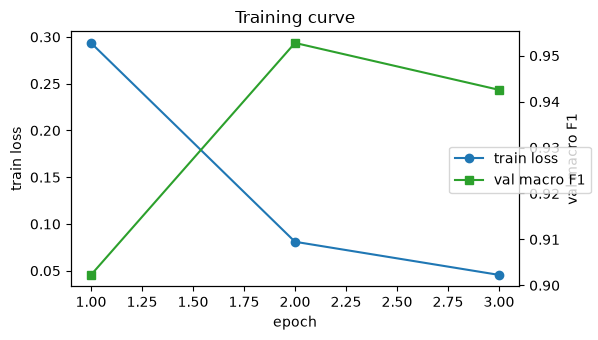

In [10]:
fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(history["epoch"], history["train_loss"], marker="o", label="train loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("train loss")
ax2 = ax1.twinx()
ax2.plot(
    history["epoch"], history["val_macro_f1"], marker="s", color="tab:green", label="val macro F1"
)
ax2.set_ylabel("val macro F1")
fig.legend(loc="center right")
ax1.set_title("Training curve")
plt.tight_layout()

## 4. Export to ONNX and int8

The service runs ONNX Runtime on CPU with no PyTorch. Two parity checks guard the export:

* **Logits parity**: ONNX and PyTorch give the same logits on the same input.
* **Tokenizer parity**: the service tokenizer (Rust `tokenizers` + tokenizer.json)
  produces exactly the token ids the model was trained on.

Dynamic int8 quantisation makes the model about 4x smaller and faster on CPU. It ships
only if validation macro F1 drops by less than 0.005.

In [11]:
bert_dir = ARTIFACTS / "distilbert"
fp32_dir, int8_dir = ARTIFACTS / "bundle-fp32", ARTIFACTS / "bundle-int8"

# The tracer warns that some shape checks become constants in the graph. The parity
# check below runs a different batch and sequence length to confirm they are harmless.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", torch.jit.TracerWarning)
    warnings.filterwarnings("ignore", message="Exporting aten::index operator")
    export.export_onnx(bert_dir, fp32_dir)
parity_texts = list(val_df["text"].iloc[:64])
max_diff = export.logits_parity(bert_dir, fp32_dir, parity_texts)
tok_mismatches = export.tokenizer_parity(bert_dir, fp32_dir, list(val_df["text"]))
print(f"max |logit diff| torch vs ONNX: {max_diff:.2e}")
print(f"tokenizer mismatches on validation: {tok_mismatches}")
assert max_diff < 1e-4 and tok_mismatches == 0

export.quantize_int8(fp32_dir, int8_dir)
for d in (fp32_dir, int8_dir):
    print(f"{d.name}: {(d / 'model.onnx').stat().st_size / 2**20:.1f} MiB")

max |logit diff| torch vs ONNX: 2.86e-06
tokenizer mismatches on validation: 0


bundle-fp32: 255.5 MiB
bundle-int8: 64.3 MiB


The ONNX models are scored **one message per call**, exactly as the service runs them.
This matters for int8. Dynamic quantisation picks its activation scale from the whole
input tensor, padding included, so the same message can be classified differently in a
padded batch than on its own. (fp32 gives identical results either way.) The
regression gate caught this: an earlier version of this notebook scored batches of 64
and reported a lower int8 F1 than the gate measured through the real service.

In [12]:
def onnx_predict(bundle_dir, texts):
    clf = Classifier(bundle_dir)
    probs = np.concatenate([clf.predict_proba([t]) for t in texts])
    return [clf.labels[i] for i in probs.argmax(axis=1)], probs


val_texts = list(val_df["text"])
val_fp32 = evaluate(val_df["label"], onnx_predict(fp32_dir, val_texts)[0])
val_int8 = evaluate(val_df["label"], onnx_predict(int8_dir, val_texts)[0])
drop = val_fp32["macro_f1"] - val_int8["macro_f1"]
print(
    f"val macro F1  fp32 {val_fp32['macro_f1']:.4f}  int8 {val_int8['macro_f1']:.4f}  "
    f"drop {drop:+.4f}"
)
SHIP_INT8 = drop < 0.005
print("ship int8" if SHIP_INT8 else "int8 loses too much accuracy, ship fp32")

val macro F1  fp32 0.9528  int8 0.9531  drop -0.0004
ship int8


## 5. Final evaluation on the test set

Everything above was decided on train and validation. The test set is scored once,
here.

In [13]:
test_texts = list(test_df["text"])
bert_probs = predict_proba(bert, tokenizer, test_texts, cfg.max_len)
int8_pred, int8_probs = onnx_predict(int8_dir, test_texts)

results = {
    "TF-IDF + LogReg": evaluate(test_df["label"], baseline_model.predict(test_df["text"])),
    "DistilBERT (PyTorch)": evaluate(test_df["label"], [LABELS[i] for i in bert_probs.argmax(1)]),
    "DistilBERT ONNX fp32": evaluate(test_df["label"], onnx_predict(fp32_dir, test_texts)[0]),
    "DistilBERT ONNX int8": evaluate(test_df["label"], int8_pred),
}
table = pd.DataFrame([summary_row(name, r) for name, r in results.items()]).set_index("model")
(REPO / "ml" / "results.json").write_text(json.dumps(results, indent=2) + "\n")
table

,macro_f1,fpr,smishing_recall,smishing_precision,spam_f1
model,,,,,
TF-IDF + LogReg,0.8547,0.0043,0.8400,0.8630,0.7241
DistilBERT (PyTorch),0.8806,0.0014,0.8533,0.9014,0.7731
DistilBERT ONNX fp32,0.8806,0.0014,0.8533,0.9014,0.7731
DistilBERT ONNX int8,0.8901,0.0014,0.8800,0.9041,0.7863


### How precise are these numbers?

The minority classes are small in the test set (about 60-75 messages each), so one
message more or less moves a class's F1 by more than a point. That also explains most of
the gap between validation and test. A bootstrap over the test set shows the range.

Overlapping intervals for two models do not settle which one is better, because both
are scored on the same messages. The comparison uses a **paired** bootstrap: each
resample scores both models on the same messages, and the difference is what counts.

In [14]:
def paired_bootstrap(y_true, pred_a, pred_b, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    y, a, b = np.asarray(y_true), np.asarray(pred_a), np.asarray(pred_b)
    rows = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        ra, rb = evaluate(y[idx], a[idx]), evaluate(y[idx], b[idx])
        rows.append((ra["macro_f1"], rb["macro_f1"], ra["fpr"], rb["fpr"]))
    return np.array(rows)


def ci(x):
    return np.round(np.percentile(x, [2.5, 97.5]), 4)


base_name, bert_name = "TF-IDF + LogReg", "DistilBERT ONNX int8"
boot = paired_bootstrap(test_df["label"], baseline_model.predict(test_df["text"]), int8_pred)

f1_diff, fpr_diff = boot[:, 1] - boot[:, 0], boot[:, 3] - boot[:, 2]
print(
    f"DistilBERT minus baseline, macro F1: {f1_diff.mean():+.4f}, 95% CI {ci(f1_diff)}; "
    f"DistilBERT ahead in {(f1_diff > 0).mean():.0%} of resamples"
)
print(f"DistilBERT minus baseline, FPR:      {fpr_diff.mean():+.4f}, 95% CI {ci(fpr_diff)}")

pd.DataFrame(
    [
        {
            "model": base_name,
            "macro_f1": results[base_name]["macro_f1"],
            "f1 95% CI": ci(boot[:, 0]),
            "fpr": results[base_name]["fpr"],
            "fpr 95% CI": ci(boot[:, 2]),
        },
        {
            "model": bert_name,
            "macro_f1": results[bert_name]["macro_f1"],
            "f1 95% CI": ci(boot[:, 1]),
            "fpr": results[bert_name]["fpr"],
            "fpr 95% CI": ci(boot[:, 3]),
        },
    ]
).set_index("model").round(4)

DistilBERT minus baseline, macro F1: +0.0346, 95% CI [-0.0051  0.079 ]; DistilBERT ahead in 94% of resamples
DistilBERT minus baseline, FPR:      -0.0029, 95% CI [-0.0073  0.    ]


,macro_f1,f1 95% CI,fpr,fpr 95% CI
model,,,,
TF-IDF + LogReg,0.8547,"[0.8085, 0.8965]",0.0043,"[0.0, 0.0101]"
DistilBERT ONNX int8,0.8901,"[0.8467, 0.9293]",0.0014,"[0.0, 0.0044]"


Reading this: DistilBERT is ahead of the baseline in about 19 out of 20 resamples, and it
flags a third as many legitimate messages, but the 95% interval for the F1 difference
still just includes zero. On a test set this small the honest claim is "very likely
better, and not worse". More labelled smishing data would settle it.

The int8 model scoring slightly above fp32 on test is noise (a handful of messages near
the decision boundary), not a benefit of quantisation. On validation they are level.

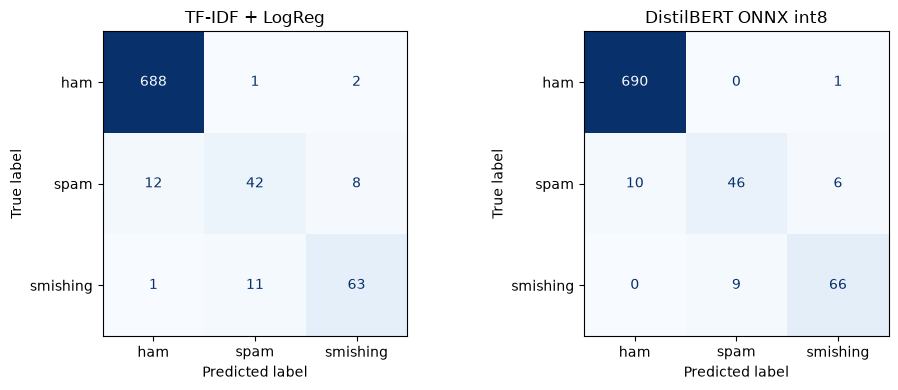

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["TF-IDF + LogReg", "DistilBERT ONNX int8"], strict=True):
    ConfusionMatrixDisplay(np.array(results[name]["confusion"]), display_labels=LABELS).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
plt.tight_layout()

## 6. Error analysis

The shipped model's mistakes on the test set, most confident first. Confident mistakes
are the interesting ones: they point at label noise or at patterns the model learned
wrongly.

In [16]:
errors = test_df.assign(pred=int8_pred, confidence=int8_probs.max(axis=1))
errors = errors[errors["label"] != errors["pred"]].sort_values("confidence", ascending=False)
print(len(errors), "errors out of", len(test_df))
errors[["label", "pred", "confidence", "text"]].head(15)

26 errors out of 828


,label,pred,confidence,text
569,spam,ham,0.998231,Would you like to see my XXX pics ...they were nearly banned in the uk!
513,spam,ham,0.997815,How come it takes so little time for a child who is afraid of the dark to become a teenager who wants to s...
432,spam,ham,0.997651,Filthy stories and GIRLS waiting for your
675,spam,ham,0.997393,"Did you hear about the new ""Divorce Barbie""? It comes with all of Ken's stuff!"
103,spam,ham,0.996610,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving..."
157,spam,ham,0.993585,For sale - arsenal dartboard. Good condition but no doubles or trebles!
736,spam,ham,0.992755,3. You have received your mobile content. Enjoy
532,spam,ham,0.991131,TBS/PERSOLVO. been chasing us since Sept for£38 definitely not paying now thanks to your information. We w...
38,spam,smishing,0.977411,We tried to contact you re your reply to our offer of a Video Phone 750 anytime any network mins Half Pric...
723,spam,smishing,0.972257,2/2 146tf150p�win tickets..call 08701417012


False positives deserve a look one by one, because each is a real message a customer
would not get:

In [17]:
errors.loc[errors["label"] == "ham", ["pred", "confidence", "text"]]

,pred,confidence,text
40,smishing,0.939891,Your account has been refilled successfully by INR 100.00; . Your KeralaCircle prepaid account balance is ...


What the errors show:

* The most confident mistakes are mostly messages labelled **spam** that the model calls
  ham. Many of them are jokes, chain messages or quizzes. Several are arguably labelled
  wrong in the source data, which caps how high spam F1 can go and is a reason not to
  chase the last points on this test set.
* **Spam and smishing overlap.** Premium-rate prize messages ("call 0870...") sit on the
  boundary. In the product both lead to action (flag or block), so this confusion costs
  less than a missed phishing message or a blocked legitimate one.
* **False positives are rare,** and the remaining ones are worth reading individually.

## CPU latency per message (the service handles one message per request)

In [18]:
def latency_ms(bundle_dir, texts, warmup=10):
    clf = Classifier(bundle_dir)
    for t in texts[:warmup]:
        clf.predict([t])
    times = []
    for t in texts:
        t0 = time.perf_counter()
        clf.predict([t])
        times.append((time.perf_counter() - t0) * 1000)
    return np.percentile(times, 50), np.percentile(times, 95)


sample_texts = test_texts[:300]
pd.DataFrame(
    [
        (d.name, *latency_ms(d, sample_texts), (d / "model.onnx").stat().st_size / 2**20)
        for d in (fp32_dir, int8_dir)
    ],
    columns=["bundle", "p50 ms", "p95 ms", "size MiB"],
).set_index("bundle").round(1)

,p50 ms,p95 ms,size MiB
bundle,,,
bundle-fp32,8.7,15.2,255.5
bundle-int8,4.3,8.4,64.3
